(quickdraw_dcgan)=
# Generating Quick, Draw! doodles with a DCGAN

This example trains a generative adversarial network to draw cats in the style of the Quick, Draw!
doodles. Two convolutional networks train against each other. A generator turns random noise into 28 by
28 images, and a discriminator scores each image as a real drawing or a generated one. The adversarial
objective is that of {cite:t}`goodfellow2014generative`, and the architecture follows the deep
convolutional GAN (DCGAN) of {cite:t}`radford2016unsupervised`.

In [1]:
import pytensor

floatX = "float32"
pytensor.config.floatX = floatX

In [2]:
import urllib.request

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pytensor.tensor as pt

from tqdm.auto import tqdm

from pytensor_ml.activations import LeakyReLU, ReLU, Tanh
from pytensor_ml.layers import (
    BatchNorm,
    Conv2D,
    ConvTranspose2D,
    Flatten,
    Input,
    Linear,
    Reshape,
    Sequential,
)
from pytensor_ml.model import Model
from pytensor_ml.optim import adam
from pytensor_ml.pytensorf import collect_shared_variables

## Data

Quick, Draw! is a collection of doodles made by players of an online game, who had 20 seconds to draw a
named object {cite:p}`ha2018sketch`. Google releases it under the CC BY 4.0 license, with each of its
345 categories available as a NumPy file of 28 by 28 grayscale bitmaps. This example uses the 123,202
drawings of cats. Pixel values run from 0 for the background to 255 for the strokes, and are rescaled to
$[-1, 1]$ for training.

In [3]:
category = "cat"
DATA_URL = f"https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/{category}.npy"
data_path = Path(f"../data/quickdraw_{category}.npy")

if not data_path.exists():
    data_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, data_path)

drawings = np.load(data_path).reshape(-1, 28, 28, 1)
images = drawings.astype(floatX) / 127.5 - 1
drawings.shape, drawings.dtype

((123202, 28, 28, 1), dtype('uint8'))

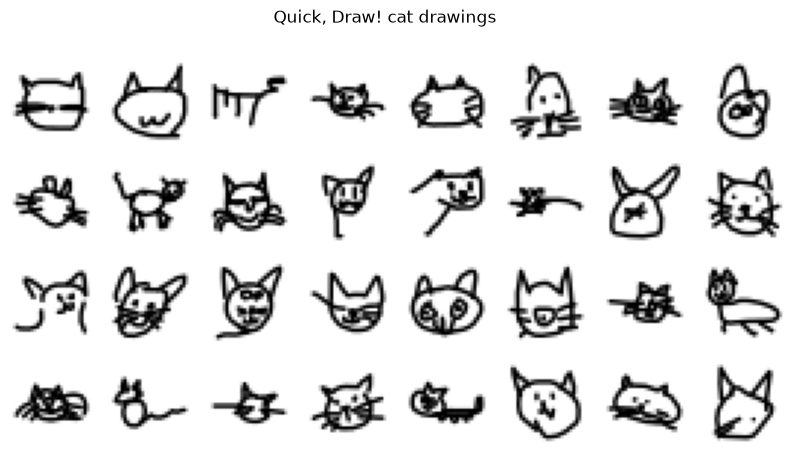

In [4]:
def plot_drawings(images, *, title, value_range):
    fig, axes = plt.subplots(nrows=4, ncols=8, figsize=(10, 5))
    for axis, image in zip(axes.flat, images):
        axis.imshow(image[..., 0], cmap="gray_r", vmin=value_range[0], vmax=value_range[1])
        axis.set_axis_off()

    fig.suptitle(title)
    plt.show()


def plot_probability_real(p_real_on_real, p_real_on_fake, *, title):
    fig, ax = plt.subplots(figsize=(7, 3.5), dpi=144, layout="constrained")
    bins = np.linspace(0, 1, 41)
    ax.hist(p_real_on_real.ravel(), bins=bins, color="C0", alpha=0.7, label="Real drawings")
    ax.hist(p_real_on_fake.ravel(), bins=bins, color="C1", alpha=0.7, label="Generator samples")
    ax.set(xlabel="Discriminator probability of real", ylabel="Images")
    ax.set_title(title, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)

    handles, labels = ax.get_legend_handles_labels()
    fig.legend(
        handles=handles,
        labels=labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.08),
        ncol=len(labels),
        frameon=False,
    )
    plt.show()


rng = np.random.default_rng(sum(map(ord, "quickdraw dcgan")))
sample_index = rng.choice(len(drawings), size=32, replace=False)

plot_drawings(
    drawings[sample_index], title=f"Quick, Draw! {category} drawings", value_range=(0, 255)
)

## Generator

The generator maps a 64-dimensional standard normal vector to a 28 by 28 image. A
{class}`~pytensor_ml.layers.Linear` layer projects the noise to 6,272 features, and
{class}`~pytensor_ml.layers.Reshape` arranges them as a 7 by 7 map with 128 channels. Two
{class}`~pytensor_ml.layers.ConvTranspose2D` layers with stride 2 double the map to 14 by 14 and then 28
by 28. Batch normalization {cite:p}`ioffe2015batchnorm` and a ReLU follow every layer but the last, and
the layers feeding a batch normalization have no bias, because the normalization subtracts it. A tanh
puts the output in $[-1, 1]$, the range of the rescaled drawings.

In [5]:
latent_dim = 64
base_channels = 64

generator = Sequential(
    Linear("generator_project", n_in=latent_dim, n_out=7 * 7 * 2 * base_channels, bias=False),
    Reshape("generator_reshape", shape=(7, 7, 2 * base_channels)),
    BatchNorm("generator_bn_7", n_in=2 * base_channels),
    ReLU(),
    ConvTranspose2D(
        "generator_up_14",
        in_channels=2 * base_channels,
        out_channels=base_channels,
        kernel_size=4,
        stride=2,
        padding=1,
        bias=False,
    ),
    BatchNorm("generator_bn_14", n_in=base_channels),
    ReLU(),
    ConvTranspose2D(
        "generator_up_28",
        in_channels=base_channels,
        out_channels=1,
        kernel_size=4,
        stride=2,
        padding=1,
    ),
    Tanh(),
)

noise = Input("noise", shape=(None, latent_dim))
fake_images = generator(noise)
fake_images.type.shape

(None, 28, 28, 1)

Before training, every generated image is close to flat gray.
{meth}`~pytensor_ml.model.Model.predict` normalizes with batch normalization's running statistics, which
start at mean 0 and variance 1, and so leave the small activations of the freshly initialized network
unscaled. The final tanh then outputs values near 0, the middle of the gray scale.

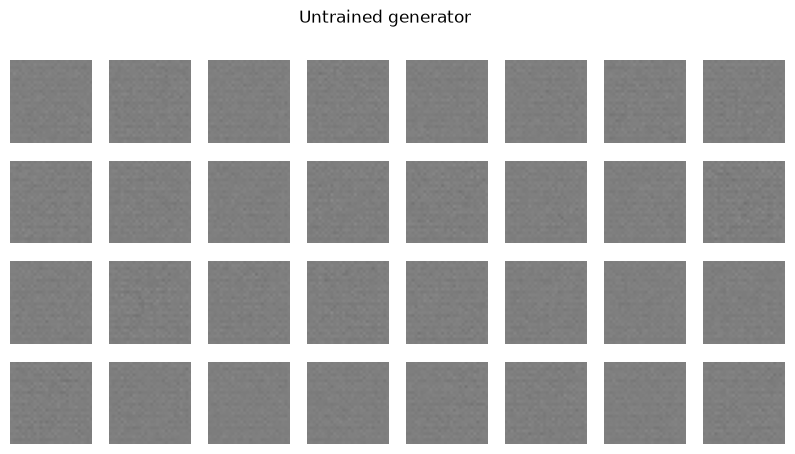

In [6]:
generator_model = Model(fake_images).initialize(seed=0)

fixed_noise = rng.normal(size=(32, latent_dim)).astype(floatX)
untrained_samples = generator_model.predict(fixed_noise)

plot_drawings(untrained_samples, title="Untrained generator", value_range=(-1, 1))

## Discriminator

The discriminator mirrors the generator. Two {class}`~pytensor_ml.layers.Conv2D` layers with stride 2
halve the image to 14 by 14 and then 7 by 7, each followed by a
{class}`~pytensor_ml.activations.LeakyReLU` with slope 0.2. Following DCGAN, the first layer has no
batch normalization. A {func}`~pytensor_ml.layers.Flatten` and a single
{class}`~pytensor_ml.layers.Linear` unit produce one logit per image.

The same discriminator scores real drawings and generated images, in two separate calls. Its batch
normalization keeps no running statistics. The discriminator is only used in training, where batch
statistics apply, and a layer that tracks running statistics feeds its first call's statistics into its
second, which would make the generator's training step read the real drawings.

In [7]:
discriminator = Sequential(
    Conv2D(
        "discriminator_down_14",
        in_channels=1,
        out_channels=base_channels,
        kernel_size=4,
        stride=2,
        padding=1,
    ),
    LeakyReLU(negative_slope=0.2),
    Conv2D(
        "discriminator_down_7",
        in_channels=base_channels,
        out_channels=2 * base_channels,
        kernel_size=4,
        stride=2,
        padding=1,
        bias=False,
    ),
    BatchNorm("discriminator_bn_7", n_in=2 * base_channels, track_running_stats=False),
    LeakyReLU(negative_slope=0.2),
    Flatten,
    Linear("discriminator_logit", n_in=7 * 7 * 2 * base_channels, n_out=1),
)

real_images = Input("real_images", shape=(None, 28, 28, 1))
real_logits = discriminator(real_images)
fake_logits = discriminator(fake_images)
real_logits.type.shape, fake_logits.type.shape

((None, 1), (None, 1))

Before training, the discriminator gives real drawings and generated images similar probabilities of
being real.

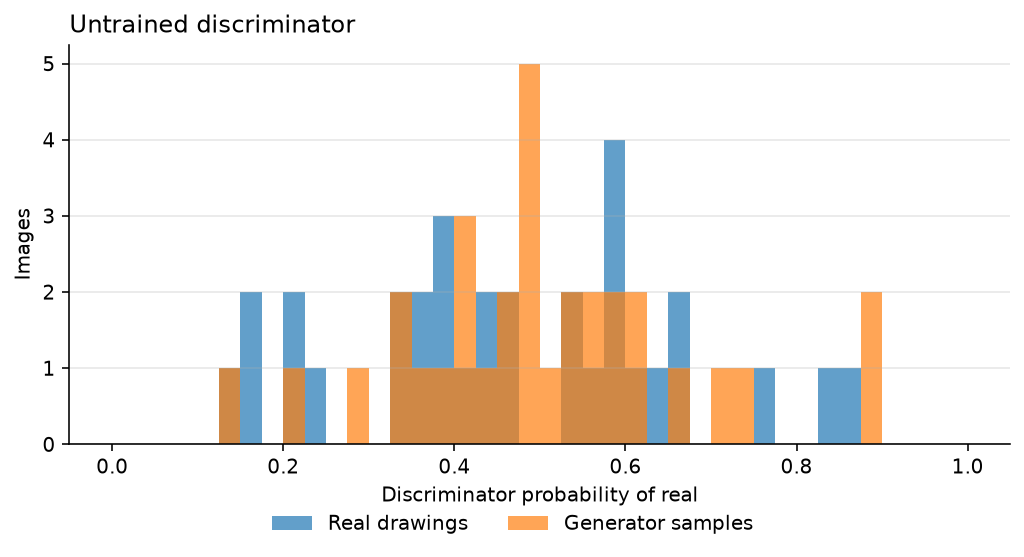

In [8]:
discriminator_model = Model(real_logits).initialize(seed=1)

probability_real = pytensor.function(
    inputs=[real_images, noise], outputs=[pt.sigmoid(real_logits), pt.sigmoid(fake_logits)]
)

p_real_on_real, p_real_on_fake = probability_real(images[sample_index], fixed_noise)
plot_probability_real(p_real_on_real, p_real_on_fake, title="Untrained discriminator")

## Training

Write $D(x)$ for the discriminator's probability that $x$ is real and $G(z)$ for the generator's image
from noise $z$. The discriminator minimizes binary cross-entropy against a target of 0.9 for real
drawings and 0 for generated ones, and the generator minimizes the cross-entropy of its own images
against the real label,

$$
\begin{aligned}
\mathcal{L}_D &= -\frac{1}{N} \sum_{i=1}^{N} \Big( 0.9 \log D(x_i) + 0.1 \log\big(1 - D(x_i)\big)
    + \log\big(1 - D(G(z_i))\big) \Big), \\
\mathcal{L}_G &= -\frac{1}{N} \sum_{i=1}^{N} \log D(G(z_i)).
\end{aligned}
$$

The generator loss is the non-saturating form of {cite:t}`goodfellow2014generative`, which gives the
generator large gradients early in training, when the discriminator rejects its images easily. The real
target of 0.9 in place of 1 is one-sided label smoothing {cite:p}`salimans2016improved`, which limits
how confident the discriminator becomes on real drawings. With $D$ the sigmoid of a logit $\ell$,
$-\log D = \operatorname{softplus}(-\ell)$ and $-\log(1 - D) = \operatorname{softplus}(\ell)$, so both
losses are written directly on the logits.

Each step is compiled from its own {class}`~pytensor_ml.model.Model`, so it updates only that network's
weights, even though both losses read both networks. Both use Adam {cite:p}`kingma2015adam` with the
DCGAN settings, a learning rate of $2 \times 10^{-4}$ and $\beta_1 = 0.5$. The steps here are compiled
for the MLX backend, and setting `compile_kwargs = {}` runs them on the default backend.

In [9]:
real_label = 0.9
compile_kwargs = {"mode": "MLX"}

real_term = real_label * pt.softplus(-real_logits) + (1 - real_label) * pt.softplus(real_logits)
discriminator_loss = pt.mean(real_term) + pt.mean(pt.softplus(fake_logits))
generator_loss = pt.mean(pt.softplus(-fake_logits))

discriminator_step = discriminator_model.compile_train(
    adam(learning_rate=2e-4, beta1=0.5),
    loss=discriminator_loss,
    inputs=[real_images, noise],
    compile_kwargs=compile_kwargs,
)
generator_step = generator_model.compile_train(
    adam(learning_rate=2e-4, beta1=0.5),
    loss=generator_loss,
    inputs=[noise],
    compile_kwargs=compile_kwargs,
)

Each iteration takes one discriminator step on a batch of real drawings and a batch of generated images,
then one generator step on fresh noise.

In [10]:
n_steps = 20_000
batch_size = 256

discriminator_losses, generator_losses = [], []

for _ in tqdm(range(n_steps)):
    batch_index = rng.integers(len(images), size=batch_size)
    discriminator_noise = rng.normal(size=(batch_size, latent_dim)).astype(floatX)
    generator_noise = rng.normal(size=(batch_size, latent_dim)).astype(floatX)

    discriminator_losses.append(
        np.array(discriminator_step(images[batch_index], discriminator_noise))
    )
    generator_losses.append(np.array(generator_step(generator_noise)))

print(
    f"final discriminator loss {discriminator_losses[-1]:.3f}, generator loss {generator_losses[-1]:.3f}"
)

  0%|          | 0/20000 [00:00<?, ?it/s]

final discriminator loss 0.382, generator loss 4.220


## Results

The losses never settle to a minimum, because each network's objective changes as the other trains. The
discriminator gains a little on every step until the generator loss climbs, and the climb ends in a
short burst where the two networks overcorrect each other for a few steps. The bursts show as spikes in
the per-step losses, and training recovers from each one.

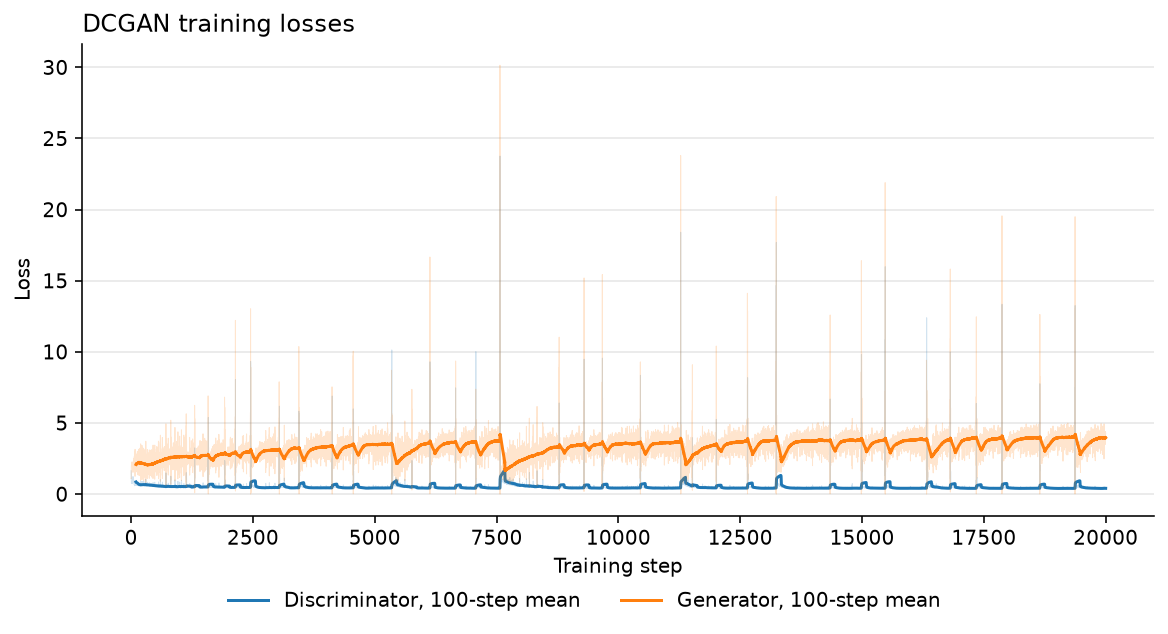

In [11]:
window = 100
smoothing_kernel = np.ones(window) / window

fig, ax = plt.subplots(figsize=(8, 4), dpi=144, layout="constrained")
for name, losses, color in [
    ("Discriminator", discriminator_losses, "C0"),
    ("Generator", generator_losses, "C1"),
]:
    ax.plot(losses, color=color, alpha=0.2, linewidth=0.5)
    ax.plot(
        np.arange(window - 1, len(losses)),
        np.convolve(losses, smoothing_kernel, mode="valid"),
        color=color,
        label=f"{name}, {window}-step mean",
    )

ax.set(xlabel="Training step", ylabel="Loss")
ax.set_title("DCGAN training losses", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles=handles,
    labels=labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=len(labels),
    frameon=False,
)
plt.show()

The training steps were compiled for the MLX backend, which writes its updates back into the shared
variables as MLX arrays. Converting every weight and statistic back to a NumPy array lets the default
backend compile the prediction functions below.

In [12]:
for variable in collect_shared_variables([fake_logits, real_logits]):
    variable.set_value(np.asarray(variable.get_value()))

The same 32 noise vectors that produced flat gray before training now produce cat drawings.

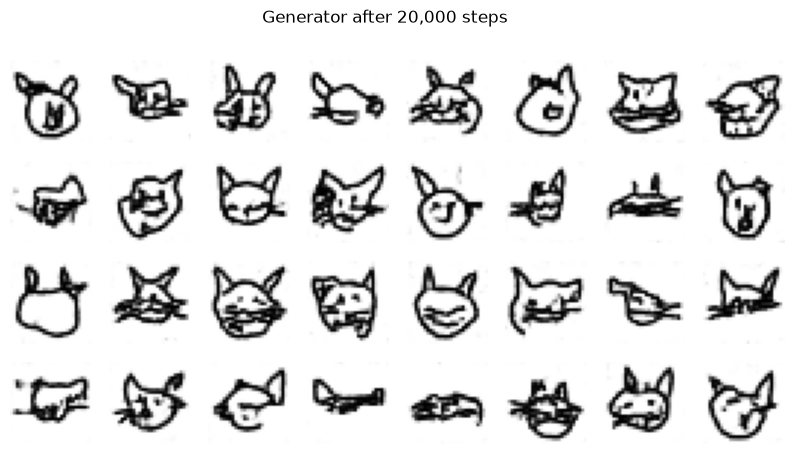

In [13]:
trained_samples = generator_model.predict(fixed_noise)

plot_drawings(trained_samples, title=f"Generator after {n_steps:,} steps", value_range=(-1, 1))

The trained discriminator scores the same real drawings and generated images as before training. The
real targets of 0.9 cap how confident it can usefully be on real drawings, so their probabilities
cluster around 0.9, the smoothed target.

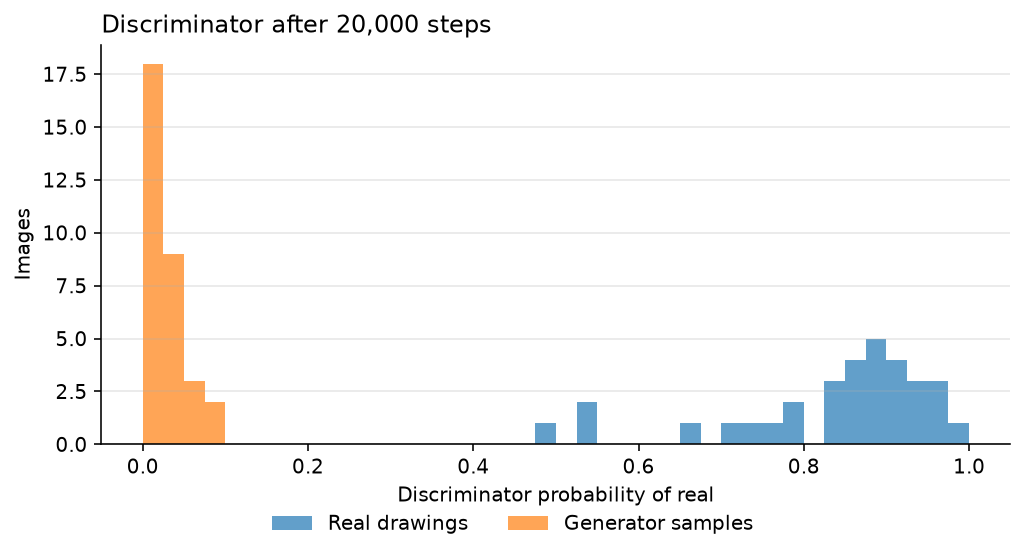

In [14]:
p_real_on_real, p_real_on_fake = probability_real(images[sample_index], fixed_noise)
plot_probability_real(
    p_real_on_real, p_real_on_fake, title=f"Discriminator after {n_steps:,} steps"
)

## References

```{bibliography}
```

## Authors

- Created by Jesse Grabowski, November 8, 2026

## Watermark

In [15]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Sun, 08 Nov 2026

Python implementation: CPython
Python version       : 3.14.10
IPython version      : 9.16.1

Compiler    : Clang 20.1.8 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

matplotlib : 3.11.2
numpy      : 2.5.4
pytensor   : 3.3.8
pytensor_ml: 0.4.0
tqdm       : 4.70.1

Watermark: 2.6.0

